# ML_prac-5

## Name :- Anuj Thakre
## Class :- A-A2-20
## Roll no :- 20 , 729097

In [16]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import (train_test_split,GridSearchCV,cross_val_score,StratifiedKFold)
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier

from sklearn.metrics import (accuracy_score,precision_score,recall_score,f1_score,confusion_matrix,classification_report)

import warnings 
warnings.filterwarnings("ignore")
sns.set_theme(style = "whitegrid")

df = pd.read_csv("diabetes.csv")

In [24]:
zero_columns = ["Glucose", "BloodPressure", "SkinThickness", "Insulin", "BMI"]

zero_counts = (df[zero_columns]==0).sum()

print("Zero values:")
print(zero_counts)


Zero values:
Glucose            5
BloodPressure     35
SkinThickness    227
Insulin          374
BMI               11
dtype: int64


In [25]:
df_clean = df.copy()
df_clean[zero_columns] = df_clean[zero_columns].replace(0,np.nan)
print("mising values after replacing invalid zeroes")
print(df_clean.isnull().sum())

mising values after replacing invalid zeroes
Pregnancies                   0
Glucose                       5
BloodPressure                35
SkinThickness               227
Insulin                     374
BMI                          11
DiabetesPedigreeFunction      0
Age                           0
Outcome                       0
dtype: int64


In [26]:

for col in zero_columns:
  df_clean[col] = df_clean[col].fillna(df_clean[col].median())

print("Missinng values after median imputation")
print(df_clean.isnull().sum())

Missinng values after median imputation
Pregnancies                 0
Glucose                     0
BloodPressure               0
SkinThickness               0
Insulin                     0
BMI                         0
DiabetesPedigreeFunction    0
Age                         0
Outcome                     0
dtype: int64


In [28]:
X = df_clean.drop("Outcome", axis=1)

y = df_clean["Outcome"]

print("X shape", X.shape)
print("y shape", y.shape)

X shape (768, 8)
y shape (768,)


In [31]:
X_train,X_test, y_train,y_test = train_test_split(X,y,test_size =0.20,random_state=42,stratify=y)

print("Training samples :- ", X_train.shape[0])
print("Testing samples :- ", X_test.shape[0])

Training samples :-  614
Testing samples :-  154


In [32]:
print("Training distributions :- ")
print(y_train.value_counts(normalize=True))

print("\n Testing distributions :- ")
print(y_test.value_counts(normalize=True))

Training distributions :- 
0    0.651466
1    0.348534
Name: Outcome, dtype: float64

 Testing distributions :- 
0    0.649351
1    0.350649
Name: Outcome, dtype: float64


In [49]:
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

scaler.fit_transform(X_test)
scaler.transform(X_test)

comparision = pd.DataFrame({
    "Original Mean" : X_train.mean(),
    "Original Std" : X_train.std(),
    "Scaled Mean" : X_train_scaled.mean(),
    "Scaled Std" : X_train_scaled.std()
})

In [50]:
scaler.fit_transform(X_test)

array([[ 0.85252995,  1.16484536, -0.8288433 , ..., -0.71933141,
        -0.46562514,  0.63400979],
       [ 1.69054875, -1.66920722,  2.88630463, ...,  0.42561436,
        -0.49253293,  1.24533587],
       [-0.54416805,  0.01253827,  0.23262754, ...,  0.48215489,
         0.09943846, -0.58864236],
       ...,
       [-0.54416805, -1.23319913, -1.89031414, ..., -0.56384494,
         3.73497988, -0.67597466],
       [ 0.01451115,  1.94343123,  0.40953934, ...,  0.63764135,
        -0.55531777, -0.15198088],
       [-0.82350765, -1.57577692,  0.40953934, ...,  0.1005063 ,
        -0.08293657, -1.02530385]])

In [51]:
scaler.transform(X_test)

array([[ 0.85252995,  1.16484536, -0.8288433 , ..., -0.71933141,
        -0.46562514,  0.63400979],
       [ 1.69054875, -1.66920722,  2.88630463, ...,  0.42561436,
        -0.49253293,  1.24533587],
       [-0.54416805,  0.01253827,  0.23262754, ...,  0.48215489,
         0.09943846, -0.58864236],
       ...,
       [-0.54416805, -1.23319913, -1.89031414, ..., -0.56384494,
         3.73497988, -0.67597466],
       [ 0.01451115,  1.94343123,  0.40953934, ...,  0.63764135,
        -0.55531777, -0.15198088],
       [-0.82350765, -1.57577692,  0.40953934, ...,  0.1005063 ,
        -0.08293657, -1.02530385]])

In [53]:
comparison = pd.DataFrame({
    "Original mean" : X_train.mean(),
    "Original std" : X_train.std(),
    "Scaled mean" : X_train_scaled.mean(axis=0),
    "SCaled std" : X_train_scaled.std(axis=0)

})

display(comparison)

,Original mean,Original std,Scaled mean,SCaled std
Pregnancies,3.819218,3.314148,-6.943414e-17,1.0
Glucose,121.671010,30.003794,-1.099374e-16,1.0
BloodPressure,72.140065,12.275119,3.095606e-16,1.0
SkinThickness,29.042345,8.891855,-3.471707e-17,1.0
Insulin,137.705212,78.764767,-4.339634e-18,1.0
BMI,32.446743,6.824142,-1.148556e-15,1.0
DiabetesPedigreeFunction,0.477428,0.330300,-1.099374e-16,1.0
Age,33.366450,11.833438,-1.084908e-16,1.0


In [59]:
from sklearn.neighbors import KNeighborsClassifier

k = 5

knn = KNeighborsClassifier(n_neighbors=k)

knn.fit(X_train_scaled, y_train)

y_pred = knn.predict(X_test_scaled)

print("Predictions:")
print(y_pred[:20])

y_prob = knn.predict_proba(X_test_scaled)

print("Probabilities:")
print(y_prob[:20])

Predictions:
[1 0 0 1 0 0 0 1 0 1 0 1 0 0 0 1 1 0 1 0]
Probabilities:
[[0.4 0.6]
 [0.8 0.2]
 [0.8 0.2]
 [0.4 0.6]
 [1.  0. ]
 [0.8 0.2]
 [0.8 0.2]
 [0.2 0.8]
 [1.  0. ]
 [0.4 0.6]
 [0.6 0.4]
 [0.4 0.6]
 [1.  0. ]
 [1.  0. ]
 [1.  0. ]
 [0.4 0.6]
 [0.2 0.8]
 [1.  0. ]
 [0.  1. ]
 [0.8 0.2]]


In [60]:
accuracy = accuracy_score(y_test,y_pred)
precision = precision_score(y_test,y_pred)
recall = recall_score(y_test,y_pred)

print("Accuracy:",accuracy)
print("Precision:",precision)
print("Recall:",recall)

Accuracy: 0.7532467532467533
Precision: 0.66
Recall: 0.6111111111111112


In [61]:
print(classification_report(y_test,y_pred,target_names=["No Diabetes","Diabetes"]))

              precision    recall  f1-score   support

 No Diabetes       0.80      0.83      0.81       100
    Diabetes       0.66      0.61      0.63        54

    accuracy                           0.75       154
   macro avg       0.73      0.72      0.72       154
weighted avg       0.75      0.75      0.75       154



In [62]:
cm = confusion_matrix(y_test,y_pred)
print(cm)


[[83 17]
 [21 33]]


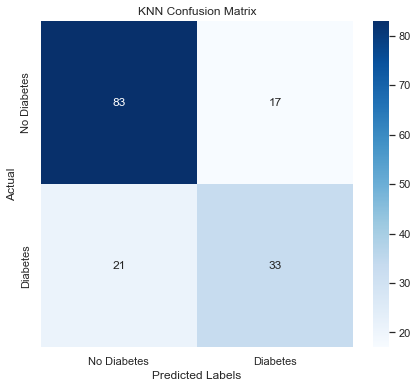

In [63]:
plt.figure(figsize=(7,6))
sns.heatmap(cm,annot=True,fmt="d",cmap="Blues",xticklabels=["No Diabetes","Diabetes"],yticklabels=["No Diabetes","Diabetes"])
plt.xlabel("Predicted Labels")
plt.ylabel("Actual")
plt.title("KNN Confusion Matrix")
plt.show()

In [64]:
k_values = range(1, 31)

train_accuracy = []
test_accuracy = []

for k in k_values:
    model = KNeighborsClassifier(n_neighbors=k)
    model.fit(X_train_scaled, y_train)

    train_accuracy.append(model.score(X_train_scaled, y_train))
    test_accuracy.append(model.score(X_test_scaled, y_test))

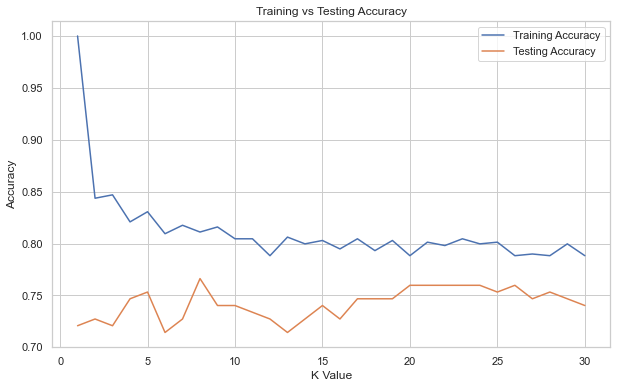

In [65]:
plt.figure(figsize=(10, 6))
plt.plot(k_values, train_accuracy, label="Training Accuracy")
plt.plot(k_values, test_accuracy, label="Testing Accuracy")
plt.xlabel("K Value")
plt.ylabel("Accuracy")
plt.title("Training vs Testing Accuracy")
plt.legend()
plt.show()

In [66]:
best_k_accuracy = k_values[np.argmax(test_accuracy)]

best_accuracy = max(test_accuracy)

print("Best K: ",best_k_accuracy)
print("Best Test Accuracy: ",best_accuracy)

Best K:  8
Best Test Accuracy:  0.7662337662337663


In [69]:
cv = StratifiedKFold(n_splits = 5, shuffle=True, random_state = 42)

cv_scores = []

for k in range(1,31):
    model = KNeighborsClassifier(n_neighbors=k)
    
    scores= cross_val_score(model, X_train_scaled,y_train, cv=cv,scoring="accuracy")
    
    cv_scores.append(scores.mean())

In [71]:
best_k_cv = np.argmax(cv_scores) +1
print("Best K Based on Cross Validation:", best_k_cv)
print("Best CV Accuracy: ",max(cv_scores))



Best K Based on Cross Validation: 13
Best CV Accuracy:  0.7703718512594963


In [70]:
param_grid = {"n_neighbors" : list(range(3,31,2)), "weights": ["uniform", "distance"],
              
        "metric" : ["euclidean", "manhattan", "minkowski"],
              
        "p" : [1,2]

}

In [73]:
grid_search = GridSearchCV(estimator = KNeighborsClassifier(),param_grid = param_grid,cv = 5,scoring = "accuracy",n_jobs =-1)

grid_search.fit(X_train_scaled,y_train)
print("Grid Search Completed")

Grid Search Completed


In [74]:
print("Best parameters :")
print(grid_search.best_params_)

Best parameters :
{'metric': 'euclidean', 'n_neighbors': 19, 'p': 1, 'weights': 'uniform'}


In [76]:
print("best Cross-validation Accuracy : ", grid_search.best_score_)

best Cross-validation Accuracy :  0.7769025723044115


In [77]:
best_knn = grid_search.best_estimator_
print(best_knn)

KNeighborsClassifier(metric='euclidean', n_neighbors=19, p=1)


In [79]:
final_pred = best_knn.predict(X_test_scaled)

final_prob = best_knn.predict_proba(X_test_scaled)[:,1]

print(final_pred)
print(final_prob)

[1 0 0 0 0 0 0 1 0 1 0 0 0 0 0 0 1 0 1 0 0 1 0 1 0 0 1 0 1 0 0 0 0 1 1 0 0
 0 1 0 0 0 0 0 0 0 0 0 1 0 0 1 0 0 1 0 1 0 1 0 1 0 0 1 0 0 1 0 0 1 0 0 0 1
 0 0 0 1 0 0 0 0 0 0 0 0 1 0 0 0 1 1 0 0 0 1 1 1 1 0 0 0 0 0 1 0 1 0 1 0 0
 1 1 0 0 0 0 0 1 0 1 0 0 1 0 1 0 1 0 0 0 0 0 1 1 0 0 0 0 0 0 0 0 0 0 0 0 1
 1 0 0 0 1 0]
[0.63157895 0.15789474 0.21052632 0.36842105 0.10526316 0.10526316
 0.31578947 0.78947368 0.         0.63157895 0.42105263 0.31578947
 0.10526316 0.26315789 0.10526316 0.42105263 0.57894737 0.
 0.78947368 0.10526316 0.31578947 0.68421053 0.31578947 0.73684211
 0.47368421 0.         0.52631579 0.         0.57894737 0.
 0.         0.         0.47368421 0.63157895 0.68421053 0.10526316
 0.10526316 0.10526316 0.68421053 0.42105263 0.42105263 0.26315789
 0.05263158 0.15789474 0.36842105 0.42105263 0.10526316 0.05263158
 0.57894737 0.26315789 0.42105263 0.57894737 0.36842105 0.05263158
 0.52631579 0.31578947 0.73684211 0.21052632 0.78947368 0.05263158
 0.68421053 0.21052632 0.1052631